# Day 2 · 01 — Lab: default training with global forecasting models (20 min)

Goals

1. **Data wrangling** — from the polars panel to what `neuralforecast` expects.
2. **Evaluative splitting** — train / validation / test, and rolling-origin cross-validation that never
   touches the test window.
3. **Default training** of global neural models, **with and without decomposition**:

| Model | Decomposition |
|---|---|
| `NHITS` | none (multi-rate pooling) |
| `NBEATS` generic (`identity` stacks) | none |
| `NBEATS` interpretable (`trend` + `seasonality` stacks) | learned trend / seasonality basis |
| `DLinear` | moving-average trend + remainder |
| `TFT` (optional, slower) | none, attention over covariates |

Everything uses library defaults apart from `max_steps`; tuning is the next lab.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl

import bootcamp as bc

warnings.filterwarnings("ignore")
import logging
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning").setLevel(logging.ERROR)

palette = ["#000000", "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#E69F00"]
plt.rcParams.update({"figure.figsize": (12, 5), "axes.prop_cycle": plt.cycler(color=palette)})

RUN_TFT = False            # TFT is ~5-10x slower on CPU; switch on if you have a GPU
print(f"max_steps={bc.MAX_STEPS} | accelerator={bc.ACCELERATOR} | n_series={bc.N_SERIES or 'all'}")

/home/user/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


max_steps=500 | accelerator=auto | n_series=all


## Intuition: why one model for 17,000 series works

![Local vs global](slides/img/global_vs_local.png)

A **local** model is a shop assistant who has only ever watched one shelf: about 90 weeks of data. A **global**
model has watched the whole store, about 180,000 weeks, so it recognises a promo spike it has seen thousands of
times, even on an item it has barely seen. The catch is that it learns *typical* behaviour; per-window scaling
and covariates are how it adapts to each item.

**N-BEATS as a relay race.** Each block explains the part of the input it can, subtracts it, and hands the rest
to the next block. The forecast is the sum of what every block carried. The *interpretable* variant forces the
first runner to be a trend and the second a season, so you can plot each piece.

![N-BEATS relay](slides/img/nbeats_relay.png)

## 1. Data wrangling

`neuralforecast` needs a **pandas** frame with `unique_id`, a datetime `ds` and `y`, on a regular grid.
Checks worth doing every time:

* one row per (`unique_id`, `ds`), no gaps inside a series (series may start late; that is fine);
* the frequency string matches the data (`W-WED` here, weeks start on Wednesday);
* the target is non-negative and the scale differs wildly between series → let the model scale each window
  (`scaler_type="robust"`) instead of scaling globally.

In [2]:
panel = bc.load_panel()
train, test = bc.split(panel)

gaps = (
    panel.group_by("unique_id")
    .agg(pl.len().alias("n"), ((pl.col("ds").max() - pl.col("ds").min()).dt.total_days() // 7 + 1).alias("span"))
    .filter(pl.col("n") != pl.col("span"))
)
dups = panel.group_by("unique_id", "ds").len().filter(pl.col("len") > 1)
print(f"series with gaps: {gaps.height} | duplicate rows: {dups.height} | weekday(s): {panel['ds'].dt.weekday().unique().to_list()}")

Y_train = bc.to_nixtla(train)
Y_test = bc.to_nixtla(test)
print(Y_train.shape, Y_test.shape)
print(panel.group_by("unique_id").agg(pl.col("y").mean()).select(pl.col("y").quantile(q).alias(f"q{q}") for q in (0.05, 0.5, 0.95)))

series with gaps: 0 | duplicate rows: 0 | weekday(s): [3]
(1596910, 3) (241374, 3)
shape: (1, 3)
┌───────────┬────────────┬──────────────┐
│ q0.05     ┆ q0.5       ┆ q0.95        │
│ ---       ┆ ---        ┆ ---          │
│ f64       ┆ f64        ┆ f64          │
╞═══════════╪════════════╪══════════════╡
│ 10.990654 ┆ 819.813084 ┆ 16276.373832 │
└───────────┴────────────┴──────────────┘


## 2. Evaluative splitting

```
2023-07 ────────────── train ────────────── 2025-01-08 ─ valid (14w) ─ 2025-04-16 ─ test (14w) ─ 2025-07-16
                                            └─ used for tuning (Lab 02) ┘           └─ scored once ┘
```

* The validation window is for **choosing** things (hyperparameters in Lab 02). Passing `val_size=bc.H` to
  `fit` removes those 14 weeks from training; it only pays off with early stopping
  (`early_stop_patience_steps`) or a search. Here we train for a fixed `max_steps`, so we train on all
  training weeks and leave `val_size` out.
* `cross_validation` on the **training** data gives rolling-origin estimates for model choice.
* The test window is scored once, by `bc.record`.

In [3]:
from neuralforecast import NeuralForecast
from neuralforecast.models import DLinear, NBEATS, NHITS, TFT

common = dict(h=bc.H, max_steps=bc.MAX_STEPS, random_seed=bc.RANDOM_SEED, **bc.trainer_kwargs())

cv_nf = NeuralForecast(models=[NHITS(input_size=2 * bc.H, scaler_type="robust", **common)], freq=bc.FREQ)
cv = cv_nf.cross_validation(df=Y_train, n_windows=2, step_size=bc.H)
bc.save_raw(cv, "01_gfm_default", "cv")          # backtest forecasts with actuals and cutoffs
cv_scores = []
for cutoff, g in cv.groupby("cutoff"):
    hist = Y_train[Y_train["ds"] <= cutoff]
    s = bc.summarise(bc.score(g.drop(columns=["cutoff", "y"]), g[["unique_id", "ds", "y"]], hist, ["NHITS"]))
    cv_scores.append(s.assign(cutoff=cutoff.date()))
pd.concat(cv_scores)[["cutoff", "model", "mean_rmsse", "median_rmsse"]]

2026-11-21 21:26:17,082	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-11-21 21:26:17,255	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


,cutoff,model,mean_rmsse,median_rmsse
0,2024-09-25,NHITS,2.089438,0.918789
0,2025-01-01,NHITS,1.598135,0.697289


The two folds disagree a lot. That is not randomness in the model: it is how much **harder one 14-week
period is than another** (the first fold runs through Christmas). Two lessons: a single 14-week test window is a
small sample, so do not over-read small gaps on the leaderboard; and compare models on the **same** windows.
The noise floor for comparing two settings of the same model (seed-to-seed variation) is measured in Lab 02.

## 3. Default training: with and without decomposition

In [4]:
models = [
    NHITS(input_size=2 * bc.H, scaler_type="robust", **common),
    NBEATS(input_size=2 * bc.H, stack_types=["identity", "identity", "identity"], scaler_type="robust",
           alias="NBEATS_generic", **common),
    NBEATS(input_size=2 * bc.H, stack_types=["trend", "seasonality"], scaler_type="robust",
           alias="NBEATS_interpretable", **common),
    DLinear(input_size=2 * bc.H, scaler_type="robust", **common),
]
if RUN_TFT:
    models.append(TFT(input_size=2 * bc.H, scaler_type="robust", **common))

fit_seconds = {}
fcst = None
for m in models:
    nf = NeuralForecast(models=[m], freq=bc.FREQ)
    with bc.Timer() as t:
        nf.fit(df=Y_train)
    name = m.alias or type(m).__name__
    fit_seconds[name] = t.seconds
    p = nf.predict()
    fcst = p if fcst is None else fcst.merge(p, on=["unique_id", "ds"])
    print(f"{name:22s} fit {t.seconds:6.1f}s")

NHITS                  fit   27.3s


NBEATS_generic         fit   25.7s


NBEATS_interpretable   fit   18.7s


DLinear                fit    3.9s


In [5]:
bc.save_forecasts(fcst, "01_gfm_default", actuals=test)
bc.save_raw(fcst, "01_gfm_default", "test", actuals=test)
bc.record(fcst, test, train, lab="01 GFM default", fit_seconds=fit_seconds)

,model,mean_rmsse,median_rmsse,mean_mase,median_mase,mean_smape,n_series,wape,bias_pct,lab,fit_seconds,notes,recorded_at
0,NHITS,1.389044,0.638116,3.846975,0.670974,0.280677,17238,0.334167,-0.029529,01 GFM default,27.301527,,2026-11-21 21:28:12
1,NBEATS_generic,1.408790,0.634459,3.964793,0.665951,0.280725,17238,0.324974,-0.055147,01 GFM default,25.672427,,2026-11-21 21:28:12
2,NBEATS_interpretable,1.409052,0.631084,3.973622,0.663204,0.283097,17238,0.324051,-0.059228,01 GFM default,18.668830,,2026-11-21 21:28:12
3,DLinear,1.593781,0.783190,4.266819,0.843667,0.331263,17238,0.443576,-0.053009,01 GFM default,3.873696,,2026-11-21 21:28:12


In [6]:
bc.leaderboard()[["model", "mean_rmsse", "median_rmsse", "wape", "bias_pct", "fit_seconds", "lab"]]

,model,mean_rmsse,median_rmsse,wape,bias_pct,fit_seconds,lab
1,LightGBM,1.353564,0.568860,0.291112,0.113513,5.597691,00 day1 reference
2,NHITS,1.389044,0.638116,0.334167,-0.029529,27.301527,01 GFM default
3,NBEATS_generic,1.408790,0.634459,0.324974,-0.055147,25.672427,01 GFM default
4,NBEATS_interpretable,1.409052,0.631084,0.324051,-0.059228,18.668830,01 GFM default
5,AutoETS,1.481539,0.694911,0.402428,0.059910,17.583231,00 day1 reference
6,Naive,1.516040,0.744972,0.420019,0.023080,17.583231,00 day1 reference
7,DLinear,1.593781,0.783190,0.443576,-0.053009,3.873696,01 GFM default
8,SeasonalNaive,1.709260,0.912763,0.445609,-0.008208,17.583231,00 day1 reference


### Reading the result

![Lab 01 results](slides/img/res_lab01.png)

* **The deep models land on top of each other** (NHITS ≈ 1.39, both N-BEATS ≈ 1.41), a little behind Day 1's
  LightGBM (≈ 1.35) with default settings. **DLinear**, a linear model, is clearly worse (≈ 1.59): weekly retail
  is not linear.
* **Interpretable = generic.** The trend + season prior costs nothing and buys plots, but 1.8 yearly cycles are
  too few to learn a season from, so it does not help accuracy.
* **Which period you test on matters more than the model.** The same NHITS scored ≈ 2.09 on the CV fold that
  runs through Christmas and ≈ 1.60 on the next one. Those folds are different periods, not different random
  seeds, so this is about how hard the window is. It is still a warning: a 0.03 gap measured on one 14-week
  window may flip on the next. The seed-to-seed noise floor comes in Lab 02.
* **Cost**: 19–27 s per neural fit (DLinear 4 s) against about 6 s for LightGBM, on all 17,241 series. The neural
  fit time does not grow with the number of series: 500 steps are 500 steps.

*Reference run: all 17,241 eligible series, 4-core laptop CPU, 500 steps. Your numbers will differ a little; the
reading should not.*

## 4. Look at the forecasts, not just the score

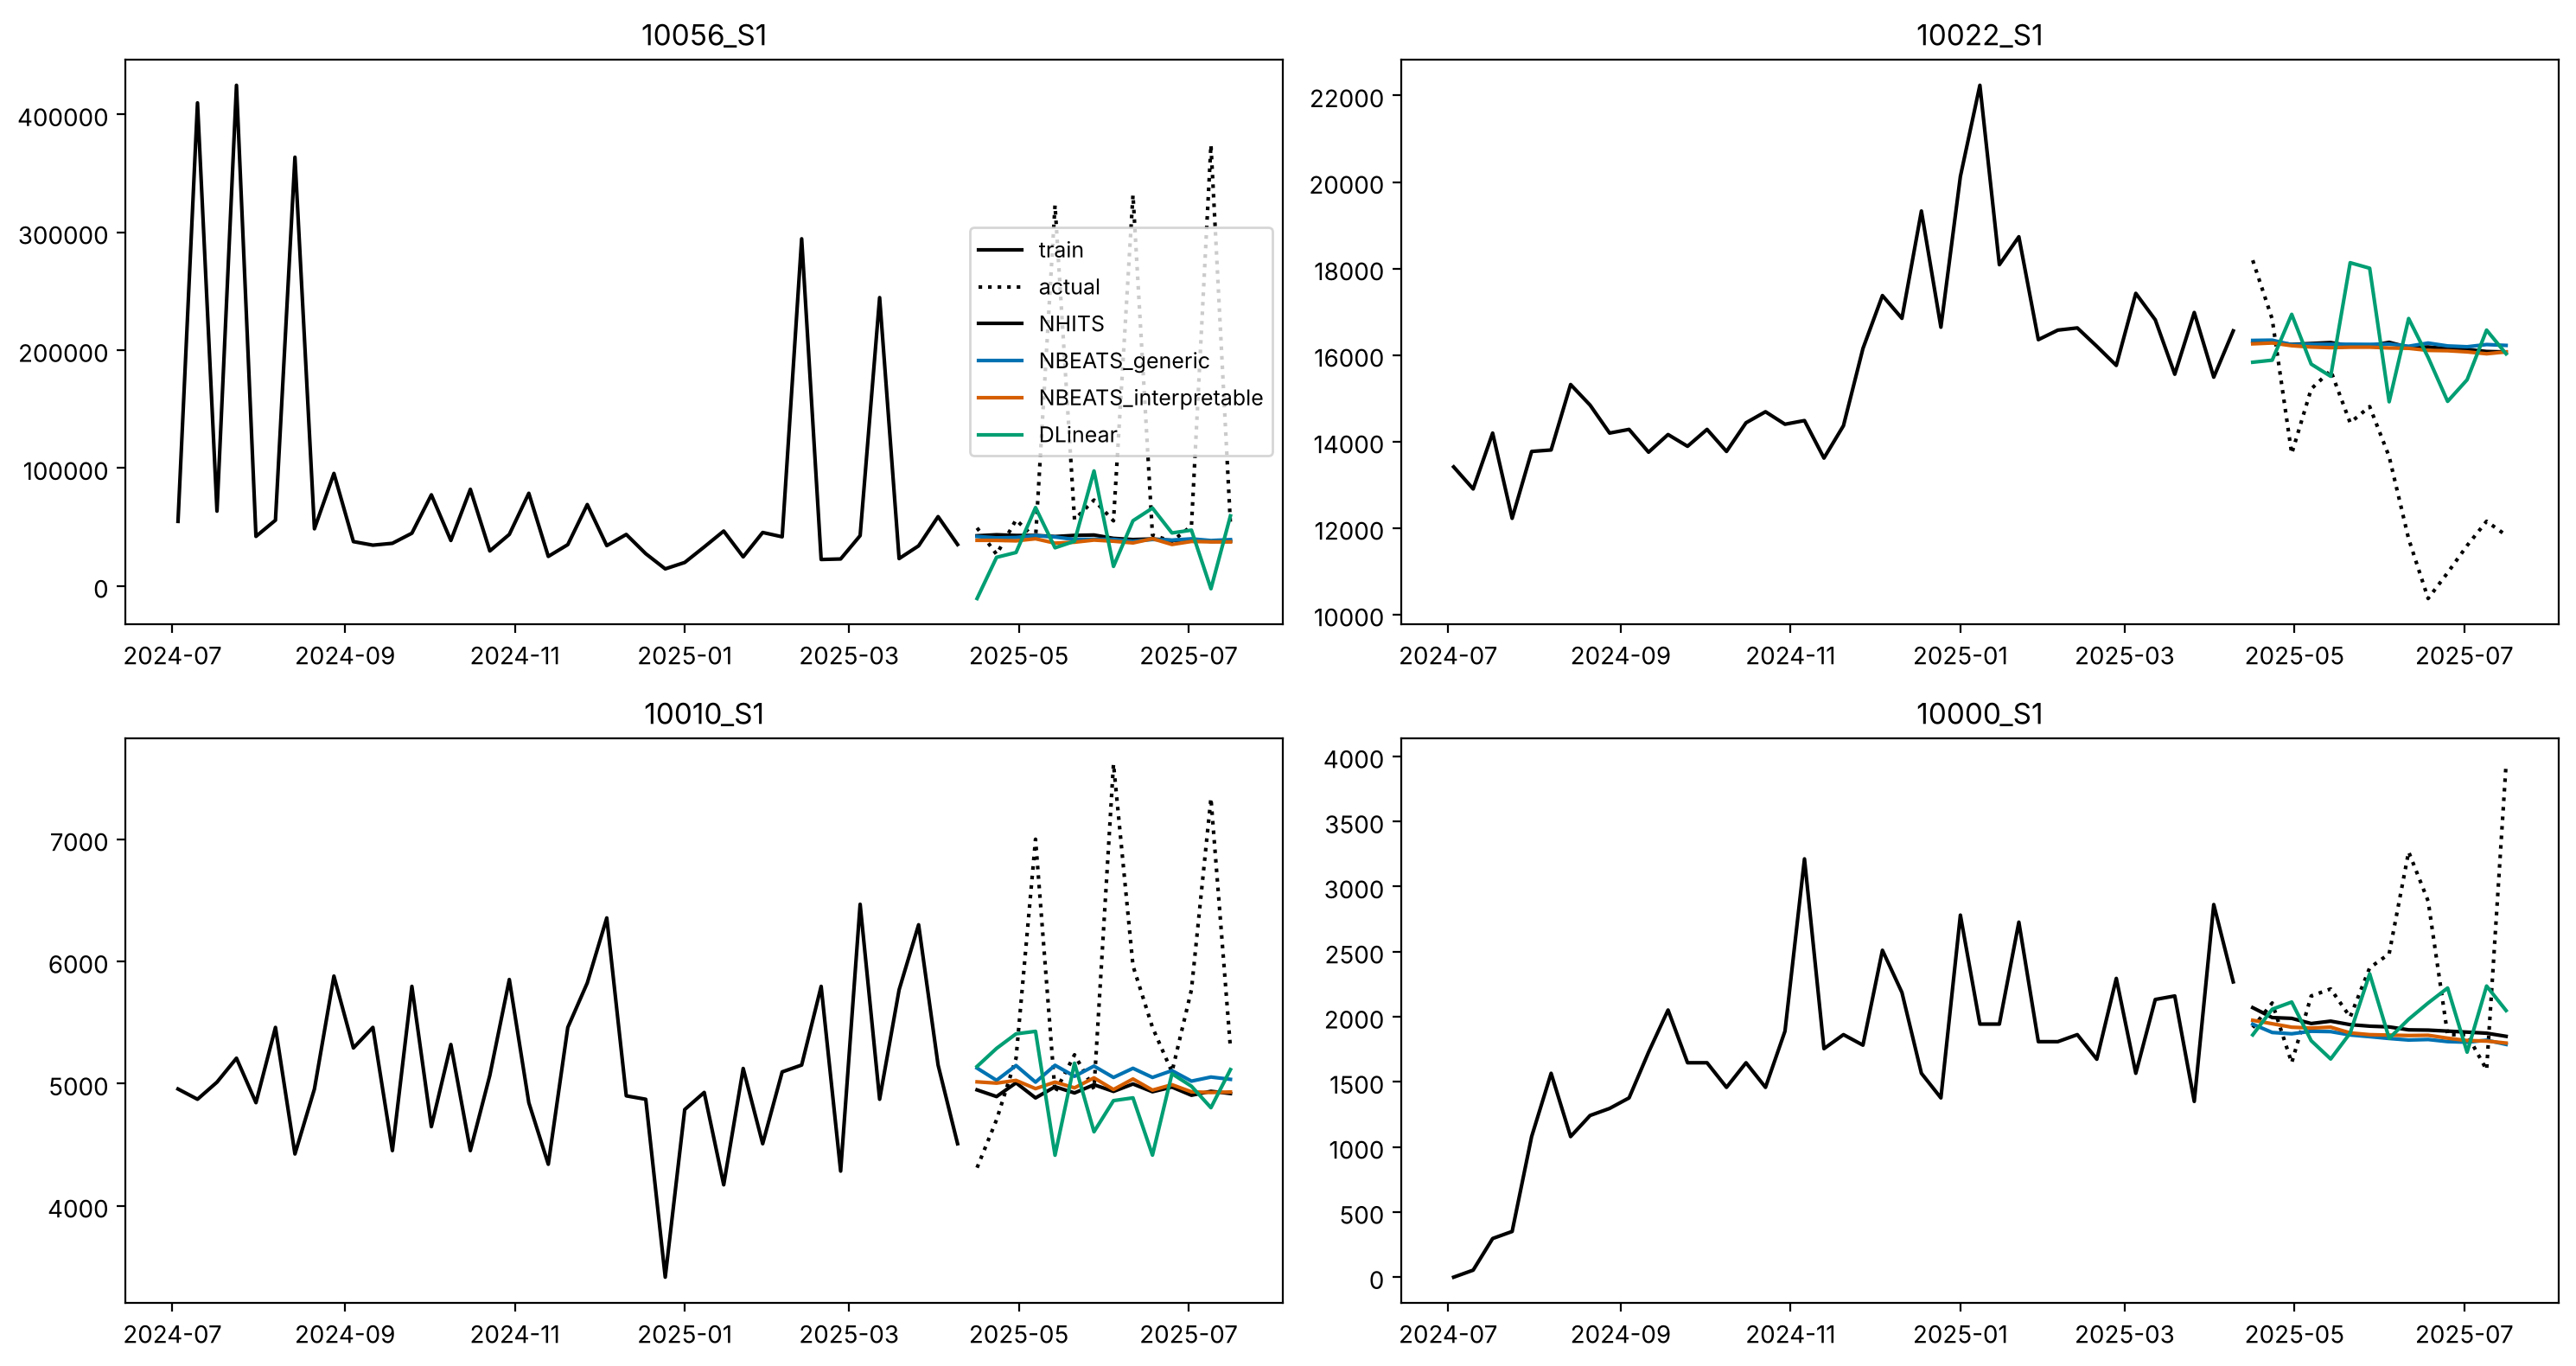

In [7]:
show = ["NHITS", "NBEATS_generic", "NBEATS_interpretable", "DLinear"]
info = bc.series_info(panel)
ids = [info.filter(pl.col("sale_class") == sc)["unique_id"][0] for sc in ["B", "E", "H", "J"]]
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, uid in zip(axes.flat, ids):
    hist = Y_train[(Y_train.unique_id == uid) & (Y_train.ds >= "2024-07-01")]
    ax.plot(hist.ds, hist.y, color="black", label="train")
    ax.plot(Y_test[Y_test.unique_id == uid].ds, Y_test[Y_test.unique_id == uid].y, color="black", ls=":", label="actual")
    f = fcst[fcst.unique_id == uid]
    for m in show:
        ax.plot(f.ds, f[m], label=m)
    ax.set_title(uid)
axes[0, 0].legend(fontsize=9)
plt.tight_layout()

## Discussion (5 min)

* Did the **decomposed** models (interpretable N-BEATS, DLinear) help or hurt against the generic ones? Note
  that N-BEATS' seasonality basis is a set of sine waves whose longest period is the 14-week horizon
  (frequencies of 1, 1.5, 2, ... cycles per 14 weeks, in the paper and in neuralforecast), so it cannot
  represent a 52-week yearly cycle at all; the interpretable variant is really "smooth trend + short cycles".
* Compare **fit time** with LightGBM from Day 1. What would the neural models need to justify the cost?
* We used `input_size = 2·h = 28` weeks. A yearly pattern needs 52+. That is the first thing we tune next.

**Try it:** set `RUN_TFT = True`, or re-run with `BOOTCAMP_MAX_STEPS=1500`, and see how far the ranking moves.